# Packages setup

In [ ]:
%pip install scikit-learn==1.9.1 catboost==1.2.10 lightgbm==4.7.0 optuna==5.0.0 shap==0.54.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 118.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 67.1 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 76.6 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1━━━━━━━━━━━━━━━━━ 1/6 [scikit-learn]
  Attempting uninstall: lightgbmm━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [scikit-learn]
    Found existing installation: lightgbm 4.6.0━━━━━━━━━━━━━━━ 1/6 [scikit-learn]
    Uninstalling lightgbm-4.6.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [scikit-learn]
      Successfully uninstalled lightgbm-4.6.0━━━━━━━━━━━━━━━━━━━━━ 2/6 [lightgbm]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [catboost]5/6 [catboost]


# Initial setup

## Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px # one-liner charts, high-level
import plotly.graph_objects as go # full control chart

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, cross_val_score
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from sklearn.base import clone

from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier, Pool

import optuna

import typing

import warnings

import joblib

## Variables

In [ ]:
TARGET = "Will_Buy_EV"
N_SPLITS = 5

def check_environment():
    try:
        import google.colab
        env = "colab"
    except ImportError:
        env = "local"
    return env

ENVIRONMENT = check_environment()

cat_columns = [
    "City_Type",
    "Current_Car_Type"
]
num_columns = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
]

yes_no_columns = ["Home_Charging_Possible", "Subsidy_Available"]
ordinal_columns = ["Range_Anxiety_Level"]
non_relevant_columns = ['id', 'source']

DRIVE_FOLDER_NAME = "EV Purchases"

## Data Loader

In [4]:
def load_data(option: str="local"):
  '''
  returns train_df, test_df, df

  '''
  if option == "local":
    train_df = pd.read_csv('../data/raw/train.csv')
    test_df = pd.read_csv('../data/raw/test.csv')

  elif option == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    train_df = pd.read_csv(f'/content/drive/MyDrive/Kaggle Practice/{DRIVE_FOLDER_NAME}/train.csv')
    test_df = pd.read_csv(f'/content/drive/MyDrive/Kaggle Practice/{DRIVE_FOLDER_NAME}/test.csv')

  train_df['source'] = 'train'
  test_df['source'] = 'test'

  df = pd.concat([train_df, test_df], ignore_index=True)

  return train_df, test_df, df

## Data Splitter

In [22]:
def data_splitter(df: pd.DataFrame, additional_drop_columns: list = []) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame]:
    '''
    return: X_train, y_train, submission_df

    '''
    train_dataset = df[df['source'] == 'train'].drop(columns=non_relevant_columns + additional_drop_columns)
    submission_dataset = df[df['source'] == 'test'].drop(columns=['source', TARGET] + additional_drop_columns)

    X_train = train_dataset.drop(columns=[TARGET])
    y_train = train_dataset[TARGET].map({"Yes": 1, "No": 0})

    return X_train, y_train, submission_dataset

## Load data

In [6]:
train_df, test_df, df = load_data(ENVIRONMENT)

Mounted at /content/drive


# Feature Engineering

In [7]:
def feature_engineering(df):

    for c in df[yes_no_columns]:
        df[c] = df[c].str.lower().map({"no": 0, "yes": 1})


    df["Range_Anxiety_Level"] = (
        df["Range_Anxiety_Level"].str.lower().map({"low": 0, "medium": 1, "high": 2})
    )

    df['Total_Charging_Stations'] = df['Charging_Stations_Near_Home'] + df['Charging_Stations_Near_Work'] + df['Home_Charging_Possible']


    df['Realistic_Concern'] = df['Environmental_Concern_Level'] - df['Range_Anxiety_Level']
    
    df["Anxiety_Environmental"] = (
    df["Range_Anxiety_Level"].astype(str)
    + "_"
    + df["Environmental_Concern_Level"].astype(str))

    df['Anxiety_Commute_Ratio'] = np.where(
        df['Daily_Commute_km'] == 0,
        0,
        df['Range_Anxiety_Level'] / df['Daily_Commute_km']
    )

    df["High_Income_EV_Potential"] = (df["Annual_Income_USD"] >= 170537.0).astype('int8')
    df['income_per_car'] = df['Annual_Income_USD'] / (df['Number_of_Cars_Owned'] + 1)



    df['subsidy_income'] = df['Annual_Income_USD'] * df['Subsidy_Available']
    df['subsidy_concern'] = df['Environmental_Concern_Level'] * df['Subsidy_Available']
    df['home_charging_subsidy'] = df['Home_Charging_Possible'] * df['Subsidy_Available']

    df = df.drop(columns='Gender')


    return df

# LightGBM training

## CV

In [13]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)

## Training Variables

In [23]:
df: pd.DataFrame
_, _, df = load_data(ENVIRONMENT)
df = feature_engineering(df)

df[["City_Type", "Current_Car_Type", "Anxiety_Environmental"]] = df[
    ["City_Type", "Current_Car_Type", "Anxiety_Environmental"]
].astype("category")


X: pd.DataFrame; y: pd.DataFrame; submission_df: pd.DataFrame
X, y, submission_df = data_splitter(df)


oof_lgb: np.ndarray = np.zeros(len(X))
fold_train_results: list[float]  = []
fold_val_results: list[float] = []
best_iters: list[int] = []

lgb_optuna_params_1: dict = {
    "n_estimators": 5000,
    "max_depth": 4,
    "learning_rate": 0.03597271512159211,
    "num_leaves": 16,
    "min_child_samples": 193,
    "subsample": 0.9146558054022962,
    "subsample_freq": 1,
    "colsample_bytree": 0.5675296747189175,
    "reg_alpha": 6.202845357521301e-08,
    "reg_lambda": 0.00015263204457498,
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cross-Validation

In [28]:
warnings.filterwarnings("ignore", module="lightgbm")

In [29]:
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):

    print(f"\n========== FOLD: {fold + 1 } ==========")
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    model: LGBMClassifier = LGBMClassifier(
        **lgb_optuna_params_1,
        random_state=42,
        objective="binary",
        metric="binary_logloss",
        verbosity=-1
    )

    model.fit(
        X=X_train,
        y=y_train,
        eval_X=X_val,
        eval_y=y_val,
        categorical_feature=cat_columns,
        callbacks=[
            early_stopping(stopping_rounds=100, verbose=False),
            log_evaluation(period=100),
        ],
    )

    fold_train_prediction = model.predict_proba(X_train)[:, 1]
    fold_val_prediction = model.predict_proba(X_val)[:, 1]

    print("Calculating AUC...")
    fold_train_auc = roc_auc_score(y_true=y_train, y_score=fold_train_prediction)
    fold_val_auc = roc_auc_score(y_true=y_val, y_score=fold_val_prediction)
    print(f"TRAIN: {fold_train_auc} | TEST: {fold_val_auc}")

    fold_train_results.append(fold_train_auc)
    fold_val_results.append(fold_val_auc)
    best_iters.append(model.best_iteration_)


print(f"\n CROSS VALIDATION ENDED")
tr_m, va_m, bi_m = (
    np.mean(fold_train_results),
    np.mean(fold_val_results),
    np.mean(best_iters),
)

tr_std, va_std, bi_std = (
    np.std(fold_train_results),
    np.std(fold_val_results),
    np.std(best_iters),
)

print(f"\n TRAIN AUC: {tr_m} +/- {tr_std}")
print(f"VAL AUC: {va_m} +/- {va_std}")
print(f"MEAN BEST ITERATION: {bi_m} +/- {bi_std}")


========== FOLD: 1 ==========
[100]	valid_0's binary_logloss: 0.235753
[200]	valid_0's binary_logloss: 0.231709
[300]	valid_0's binary_logloss: 0.23049
[400]	valid_0's binary_logloss: 0.229809
[500]	valid_0's binary_logloss: 0.229289
[600]	valid_0's binary_logloss: 0.228954
[700]	valid_0's binary_logloss: 0.228658
[800]	valid_0's binary_logloss: 0.228425
[900]	valid_0's binary_logloss: 0.228293
[1000]	valid_0's binary_logloss: 0.228135
[1100]	valid_0's binary_logloss: 0.228036
[1200]	valid_0's binary_logloss: 0.227963
[1300]	valid_0's binary_logloss: 0.22791
[1400]	valid_0's binary_logloss: 0.227862
[1500]	valid_0's binary_logloss: 0.227827
[1600]	valid_0's binary_logloss: 0.227775
[1700]	valid_0's binary_logloss: 0.227746
[1800]	valid_0's binary_logloss: 0.227739
[1900]	valid_0's binary_logloss: 0.227714
[2000]	valid_0's binary_logloss: 0.227712
[2100]	valid_0's binary_logloss: 0.227707
Calculating AUC...
TRAIN: 0.9457680359061028 | TEST: 0.9411187425035005

========== FOLD: 2 ======

KeyboardInterrupt: 

# Full Training

In [32]:
final_params: dict = {
    "n_estimators": 5000,
    "max_depth": 4,
    "learning_rate": 0.03597271512159211,
    "num_leaves": 16,
    "min_child_samples": 193,
    "subsample": 0.9146558054022962,
    "subsample_freq": 1,
    "colsample_bytree": 0.5675296747189175,
    "reg_alpha": 6.202845357521301e-08,
    "reg_lambda": 0.00015263204457498,
} 
final_model = LGBMClassifier(
    **final_params,
    random_state=42,
    objective="binary",
    metric="binary_logloss",
    verbosity=-1
)

final_model.fit(
    X=X,
    y=y,
    categorical_feature=cat_columns
)

,num_leaves,16
,max_depth,4
,learning_rate,0.03597271512159211
,n_estimators,5000
,objective,'binary'
,min_child_samples,193
,subsample,0.9146558054022962
,subsample_freq,1
,colsample_bytree,0.5675296747189175
,reg_alpha,6.202845357521301e-08
,reg_lambda,0.00015263204457498


## Save model

In [33]:
import joblib

# After training on a DataFrame X_train
bundle = {
    "model": final_model,                               # trained model
    "features": list(X.columns),                        # order
    "dtypes": X.dtypes.astype(str).to_dict(),           # type of each feature
}
joblib.dump(bundle, "model_v2.joblib")

['model_v2.joblib']

In [34]:
%pip install shap==0.54.1

In [36]:
import shap

explainer = shap.TreeExplainer(final_model)          # your fitted LGBMClassifier

X_sample = X_val.sample(5000, random_state=42) # use a sample; 500k rows is slow to plot
sv = explainer(X_sample)                       # Explanation object

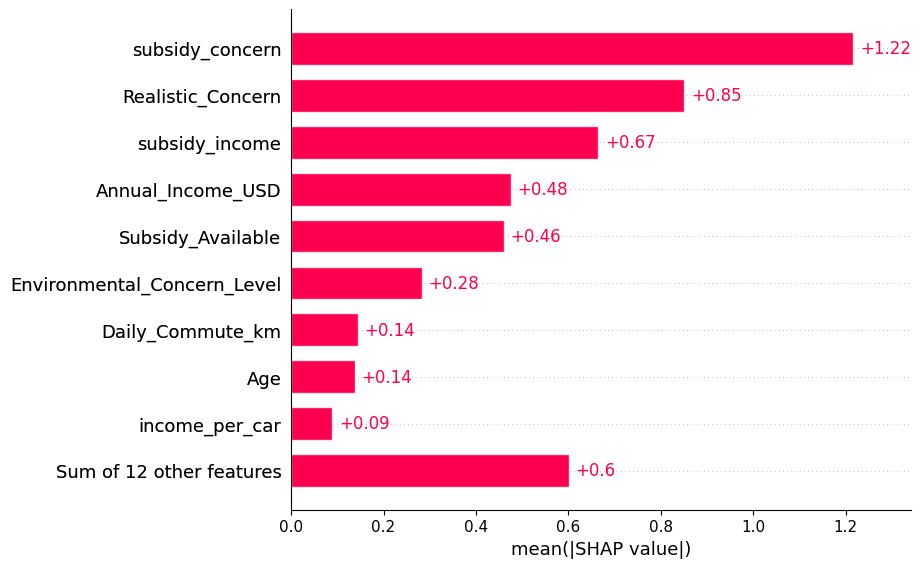

In [37]:
shap.plots.bar(sv)

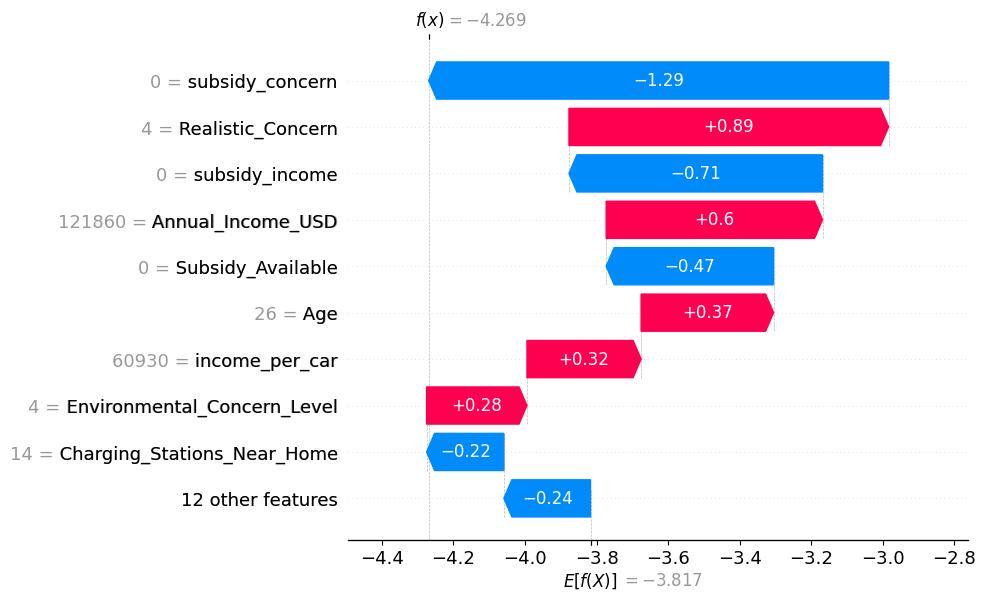

In [39]:
shap.plots.waterfall(sv[0]) 